In [5]:
from anemone.inversion import *
from anemone.experiment import *
from anemone.forwards import *

In [35]:
def parse_line(f):
    line = str(f.readline())
    if '!' in line:
        line = line[:line.index('!')]
    line = line.strip()
    if '\t' in line:
        res = line.split('\t')
        res = [x for x in res if x != '']
    elif ' ' in line:
        res = line.split(' ')
        res = [x for x in res if x != '']
    else:
        res = [line]
    if isinstance(res, list):
        res = [float(x) for x in res]
    return res

In [43]:
fname = "C:/Users/au646858/OneDrive - Aarhus universitet/Documents/repositories/anemone/prototyping/20230119.tem"
fname = r"C:\Users\au646858\Downloads\001.tem"
import numpy as np
with open(fname) as f:
    # data_entries = f.readline().split(';')
    # data_header = {}
    # for i, item in enumerate(data_entries):
    #     param, value = item.split('=')
    #     try:
    #         data_header[param] = float(value)
    #     except:
    #         data_header[param] = value
    _ = f.readline()
    _ = parse_line(f) # source type stuff
    txrx_pos = parse_line(f)
    n_seg,area = parse_line(f)
    x,y,z = [],[],[]
    for i in range(int(n_seg)):
        x_,y_ = parse_line(f)
        x.append(x_)
        y.append(y_)
        z.append(float(txrx_pos[2]))
    x.append(x[0])
    y.append(y[0])
    z.append(z[0])
    src = Loop(x,y, z)
    rx = Receiver(*txrx_pos[3:])
    rx.z = torch.abs(rx.z)

    assert all(x==3. for x in parse_line(f)), 'other data types not supported, must by in db/dt'
    wv_type,n_wv = parse_line(f)
    if wv_type==3.:
        wvs = []
        for i in range(int(n_wv)):
            wv_ = np.array(parse_line(f)[1:])
            wvs.append(Waveform( wv_[::4], wv_[2::4]))       
    if n_wv==1:
        wvs = wvs[0]
    n_filt,frontgate,frontgate_scale = parse_line(f)
    filters = []
    for i in range(int(n_filt)):
        ncut,forder,fcut = parse_line(f)
        forder = int(round(forder))
        filters.append(ButterworthFilter(fcut, forder))
        _ = parse_line(f)
    if frontgate==1:
        (fgate_time) = parse_line(f)
    for i in range(int(n_filt)):
        ncut,forder,fcut = parse_line(f)
        filters.append(ButterworthFilter(fcut, forder))
        _ = parse_line(f)
    
    data = np.fromstring(f.read(), sep=' ')
    if len(data)%5==0:
        data = data.reshape(-1,5).T
    elif len(data)%7==0:
        data = data.reshape(-1,7).T
        t_start = data[5]
        t_end   = data[6]

    t_center = torch.from_numpy(data[0]).to(torch.double)
    data_obs = torch.from_numpy(data[1]).to(torch.double)/30
    relerr   = torch.from_numpy(data[2]).to(torch.double)
    data_err = data_obs*relerr

    filters = FilterChain(filters)
    if n_wv==1:
        fwr = Forward(src, rx, t_center, waveform=wvs, filterfunc=filters, tolerance=1e-5)

    model = SmoothModel.starting_model(41, rho=200.)
    inv = Inversion(data_obs, data_err, model, fwr)
    res_mod = inv.invert(smoothness=20)


c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:108: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


torch.Size([41, 41])
001	misfit:	10.97
torch.Size([41, 41])
002	misfit:	8.77
torch.Size([41, 41])
increased max step
003	misfit:	6.90
torch.Size([41, 41])
increased max step
004	misfit:	6.20
torch.Size([41, 41])
increased max step
005	misfit:	5.75
torch.Size([41, 41])
increased max step
006	misfit:	5.48
torch.Size([41, 41])
increased max step
007	misfit:	5.29
torch.Size([41, 41])
increased max step
008	misfit:	7.37
increased max step
009	misfit:	5.31
torch.Size([41, 41])
increased max step
010	misfit:	12.95
reached iteration cap..
reached iteration cap..

 10


In [44]:
res_mod.mod

(tensor([0.0111, 0.0118, 0.0131, 0.0149, 0.0175, 0.0212, 0.0266, 0.0345, 0.0465,
         0.0649, 0.0923, 0.1310, 0.1773, 0.2152, 0.2173, 0.1728, 0.1083, 0.0574,
         0.0287, 0.0155, 0.0101, 0.0079, 0.0071, 0.0074, 0.0086, 0.0119, 0.0198,
         0.0351, 0.0525, 0.0556, 0.0432, 0.0281, 0.0175, 0.0112, 0.0077, 0.0056,
         0.0044, 0.0037, 0.0031, 0.0025, 0.0013]),
 tensor([ 0.1686,  0.1897,  0.2135,  0.2402,  0.2703,  0.3042,  0.3423,  0.3852,
          0.4335,  0.4879,  0.5490,  0.6178,  0.6953,  0.7824,  0.8805,  0.9908,
          1.1150,  1.2547,  1.4120,  1.5890,  1.7881,  2.0123,  2.2645,  2.5483,
          2.8677,  3.2271,  3.6316,  4.0867,  4.5989,  5.1753,  5.8240,  6.5540,
          7.3754,  8.2998,  9.3401, 10.5107, 11.8281, 13.3105, 14.9788, 16.8562]))

In [45]:
d_pred = fwr(*res_mod.mod)

In [46]:
d_pred

tensor([-1.4141e-05, -1.5819e-06,  3.9020e-06,  5.4224e-06,  4.9322e-06,
         3.7597e-06,  2.5779e-06,  1.6407e-06,  9.8459e-07,  5.6314e-07,
         3.0896e-07,  1.6347e-07,  8.3849e-08,  4.1857e-08,  2.0398e-08,
         9.7450e-09,  4.5698e-09], dtype=torch.float64)

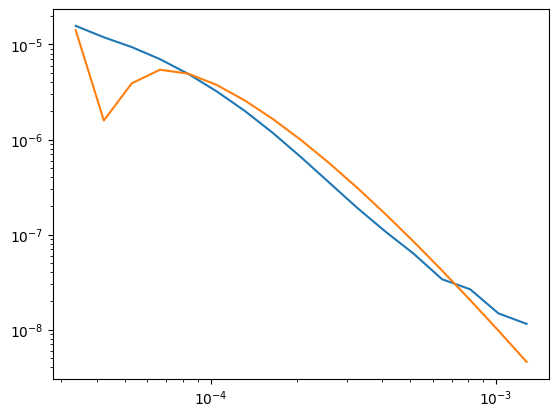

In [47]:
plt.figure()
plt.loglog(fwr.times, data_obs, label='obs')
plt.loglog(fwr.times, np.abs(d_pred.real), label='pred')


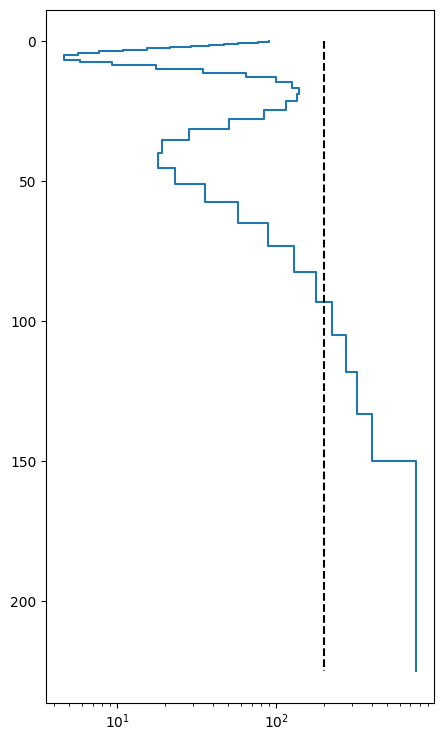

In [48]:
rho_mod = res_mod.copy()
rho_mod.values = [1/rho_mod.values[0]]

m0 = model.copy()
m0.values = [1./m0.values[0]]
import matplotlib.pyplot as plt
import numpy as np

fig,ax=plt.subplots(figsize=(5,9))
ax = rho_mod.plot(ax=ax)
m0.plot(ax=ax, linestyle='--', color='k')
ax.set_ylim(ax.get_ylim()[::-1])
ax.set_xscale('log')

In [10]:
plt.figure()
plt.plot(wv[0].time, wv[0].amplitude)

NameError: name 'wv' is not defined

<Figure size 640x480 with 0 Axes>